# BANKING77 — Data Understanding & Exploratory Data Analysis

**Project context:** Banking Conversational AI / Intent Analytics (Portfolio project).  
**Dataset:** PolyAI BANKING77 (customer utterances and labeled intents).  
**Objective:** Understand the data, detect potential quality risks, and create hypotheses for intent classification.

### Learning goals
1. Validate data structure and quality.
2. Check exact duplicates, normalized duplicates, and potential train–test overlap.
3. Explore intent frequencies and class imbalance.
4. Analyze message lengths and inspect extreme cases.
5. Review examples of potentially overlapping intents.
6. Summarize findings as an analyst, **without training a model yet**.

> These are labeled *individual utterances*, not full production conversation logs. The dataset cannot tell us actual chatbot fallback rate, API action success rate, or self-service resolution rate.

## 0. File structure
Expected project layout:

```text
Banking-Conversational-AI-Analytics/
├── .venv/
├── data/
│   └── raw/
│       ├── train.csv
│       └── test.csv
└── notebooks/
    └── 01_data_understanding_eda.ipynb
```

In [1]:
# Core libraries for data inspection and visualization.
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_colwidth", None)  # Show complete customer messages.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)
sns.set_theme(style="whitegrid")

print("pandas version:", pd.__version__)
print("Current working directory:", Path.cwd())

pandas version: 3.0.6
Current working directory: /Users/yaser/banking-conversational-ai-analytics/notebooks


## 1. Load the train and test datasets

`train.csv` will be our main EDA source. We do not inspect test-set intent patterns before evaluation.

In [2]:
# Find raw CSV files whether Jupyter runs from the project root or notebooks/.
candidate_dirs = [Path("data/raw"), Path("../data/raw")]
data_dir = next(
    (folder for folder in candidate_dirs
     if (folder / "train.csv").exists() and (folder / "test.csv").exists()),
    None,
)

if data_dir is None:
    raise FileNotFoundError(
        "Cannot find train.csv and test.csv. Place both files in data/raw/ "
        "and check your notebook working directory."
    )

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

print("Train shape (rows, columns):", train.shape)
print("Test shape (rows, columns):", test.shape)
print("Training columns:", train.columns.tolist())
display(train.head(5))

Train shape (rows, columns): (10003, 2)
Test shape (rows, columns): (3080, 2)
Training columns: ['text', 'category']


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived after 2 weeks?,card_arrival
2,I have been waiting over a week. Is the card still coming?,card_arrival
3,Can I track my card while it is in the process of delivery?,card_arrival
4,"How do I know if I will get my card, or if it is lost?",card_arrival


## 2. Check column types, missing values, and blank strings

**Why:** A model cannot learn meaningful intents from missing messages or missing labels. A blank string (`"   "`) may not appear as a missing value (`NaN`), so both checks matter.

**Questions:** Are `text` and `category` present? Are the values stored as strings? Is anything missing or empty?

In [3]:
required_columns = {"text", "category"}
if not required_columns.issubset(train.columns):
    raise ValueError(f"Training CSV must contain: {required_columns}")
if not required_columns.issubset(test.columns):
    raise ValueError(f"Test CSV must contain: {required_columns}")

print("TRAIN COLUMN INFO")
train.info()

quality_report = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing_values": train.isna().sum(),
    "blank_or_whitespace_only": train.fillna("").astype(str).apply(
        lambda series: series.str.strip().eq("").sum()
    ),
    "unique_values": train.nunique(dropna=True),
})
print("\nTRAIN DATA QUALITY")
display(quality_report)

# Blank counts above include missing values after fillna(""). They are not additive.
if train[["text", "category"]].isna().any().any():
    print("Warning: missing training values need investigation before modeling.")

TRAIN COLUMN INFO
<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      10003 non-null  str  
 1   category  10003 non-null  str  
dtypes: str(2)
memory usage: 156.4 KB

TRAIN DATA QUALITY


,dtype,missing_values,blank_or_whitespace_only,unique_values
text,str,0,0,10003
category,str,0,0,77


## 3. Detect duplicates and conflicting labels

**Why:** Repeated texts can inflate apparent model performance or lead to inconsistent supervision.

We check three different problems:
- **Exact row duplicate:** the same `text` and `category` appear again.
- **Repeated text:** the same message appears again, even if its category differs.
- **Normalized text duplicate:** casing and extra whitespace are ignored for an additional audit.

Normalized duplicates are only *candidates* for review; they are not proof of semantic duplication. **Do not delete anything automatically.**

In [4]:
print("Exact duplicate rows:", train.duplicated().sum())
print("Repeated text values:", train["text"].duplicated().sum())

# Normalization for auditing only, not a preprocessing decision for ML.
def normalize_text_for_audit(value: str) -> str:
    return re.sub(r"\s+", " ", str(value)).strip().casefold()

df = train.copy()
df["normalized_text"] = df["text"].map(normalize_text_for_audit)

normalized_duplicate_count = df["normalized_text"].duplicated().sum()
print("Repeated text after case/whitespace normalization:", normalized_duplicate_count)

# A single normalized utterance associated with multiple intent labels.
labels_per_text = df.groupby("normalized_text")["category"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
print("Normalized messages with conflicting intent labels:", len(conflicting_texts))

if len(conflicting_texts) > 0:
    display(
        df[df["normalized_text"].isin(conflicting_texts)]
        .sort_values("normalized_text")[["text", "category", "normalized_text"]]
        .head(12)
    )

Exact duplicate rows: 0
Repeated text values: 0
Repeated text after case/whitespace normalization: 4
Normalized messages with conflicting intent labels: 0


## 4. Check whether the same text occurs in train and test

**Why:** Identical messages appearing across both splits can produce misleading evaluation results. This is an **overlap audit**, not a reason to explore or tune against the test labels.

If there is overlap, document the issue and decide how to handle it **before** reporting final model metrics.

In [5]:
test_normalized = test["text"].dropna().map(normalize_text_for_audit)
train_texts = set(df["normalized_text"])
test_texts = set(test_normalized)
overlap = train_texts.intersection(test_texts)

print("Unique normalized texts shared between train and test:", len(overlap))
print("Test labels are intentionally not analyzed in this notebook.")

Unique normalized texts shared between train and test: 7
Test labels are intentionally not analyzed in this notebook.


## 5. Explore intent distribution and class balance

**Why:** Each `category` is an intent the future model may need to predict. If some intents have many more labeled examples than others, overall accuracy may hide weak performance in low-frequency categories.

A large max/min ratio is a **warning to investigate**, not automatic proof that the data must be resampled.

In [6]:
intent_counts = df["category"].value_counts()

intent_summary = pd.Series({
    "Number of intents": len(intent_counts),
    "Smallest class": int(intent_counts.min()),
    "Largest class": int(intent_counts.max()),
    "Average examples per intent": round(intent_counts.mean(), 2),
    "Median examples per intent": float(intent_counts.median()),
    "Largest/smallest class ratio": round(intent_counts.max() / intent_counts.min(), 2),
})

display(intent_summary.to_frame("Value"))
print("Top 10 most frequent intents:")
display(intent_counts.head(10).rename("count").to_frame())
print("Bottom 10 least frequent intents:")
display(intent_counts.tail(10).sort_values().rename("count").to_frame())

,Value
Number of intents,77.00
Smallest class,35.00
Largest class,187.00
Average examples per intent,129.91
Median examples per intent,127.00
Largest/smallest class ratio,5.34


Top 10 most frequent intents:


,count
category,
card_payment_fee_charged,187
direct_debit_payment_not_recognised,182
balance_not_updated_after_cheque_or_cash_deposit,181
wrong_amount_of_cash_received,180
cash_withdrawal_charge,177
transaction_charged_twice,175
declined_cash_withdrawal,173
transfer_fee_charged,172
transfer_not_received_by_recipient,171


Bottom 10 least frequent intents:


,count
category,
contactless_not_working,35
virtual_card_not_working,41
card_acceptance,59
card_swallowed,61
lost_or_stolen_card,82
compromised_card,86
atm_support,87
receiving_money,95
top_up_limits,97


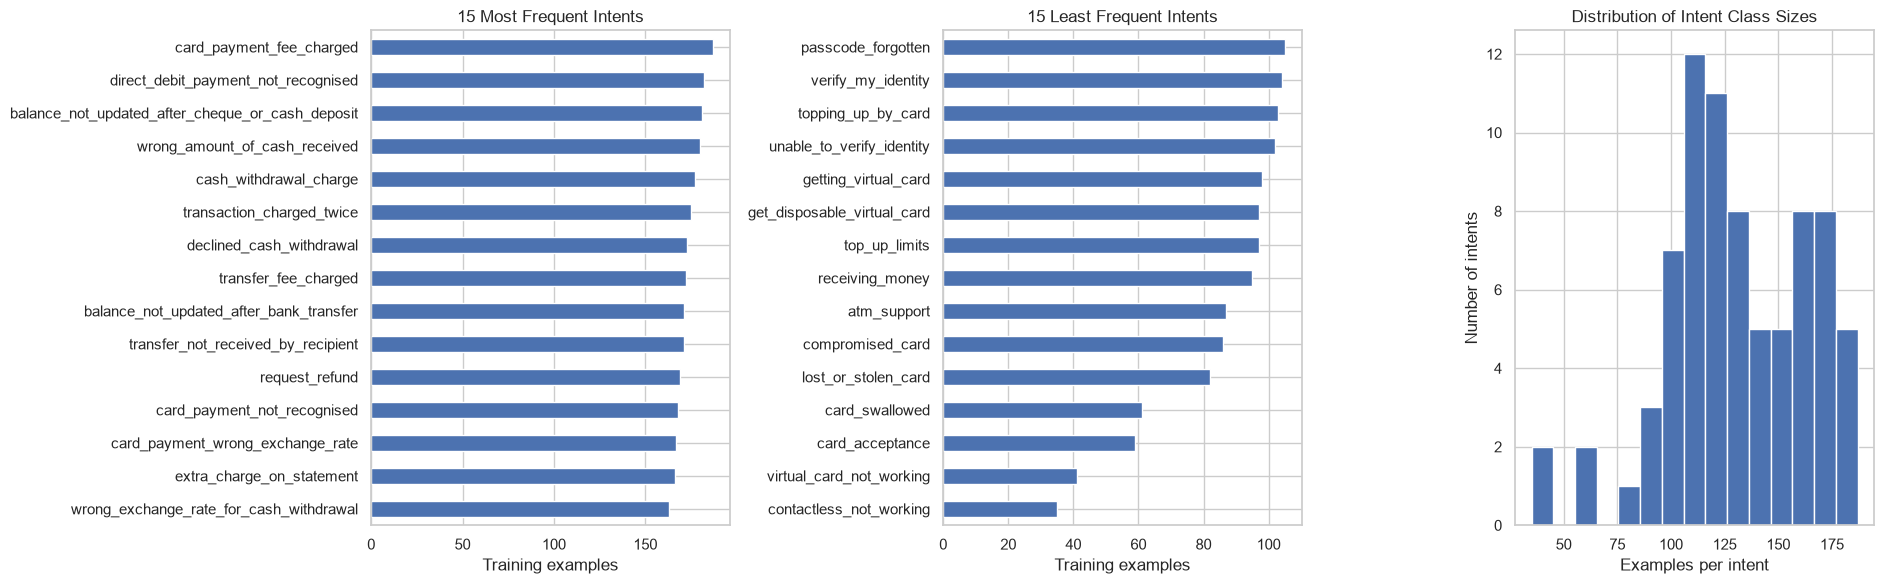

In [7]:
# Visualize the most/least represented intents and all 77 class sizes.
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

intent_counts.head(15).sort_values().plot.barh(ax=axes[0])
axes[0].set_title("15 Most Frequent Intents")
axes[0].set_xlabel("Training examples")
axes[0].set_ylabel("")

intent_counts.tail(15).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("15 Least Frequent Intents")
axes[1].set_xlabel("Training examples")
axes[1].set_ylabel("")

axes[2].hist(intent_counts.values, bins=15)
axes[2].set_title("Distribution of Intent Class Sizes")
axes[2].set_xlabel("Examples per intent")
axes[2].set_ylabel("Number of intents")

plt.tight_layout()
plt.show()

## 6. Analyze customer-message length

**Why:** Short messages may lack context; very long messages may contain complex or multiple requests. These are **hypotheses**, not established causes of model errors.

We measure:
- `word_count`: whitespace-separated words (a simple approximation, not a linguistic tokenizer).
- `char_count`: total characters, including spaces and punctuation.

We retain unusually short and long messages until we inspect them.

Word and character length statistics:


,count,mean,std,min,25%,50%,75%,max
word_count,10003.0,11.949415,7.891577,2.0,7.0,10.0,13.0,79.0
char_count,10003.0,59.473758,40.867901,13.0,36.0,47.0,64.0,433.0


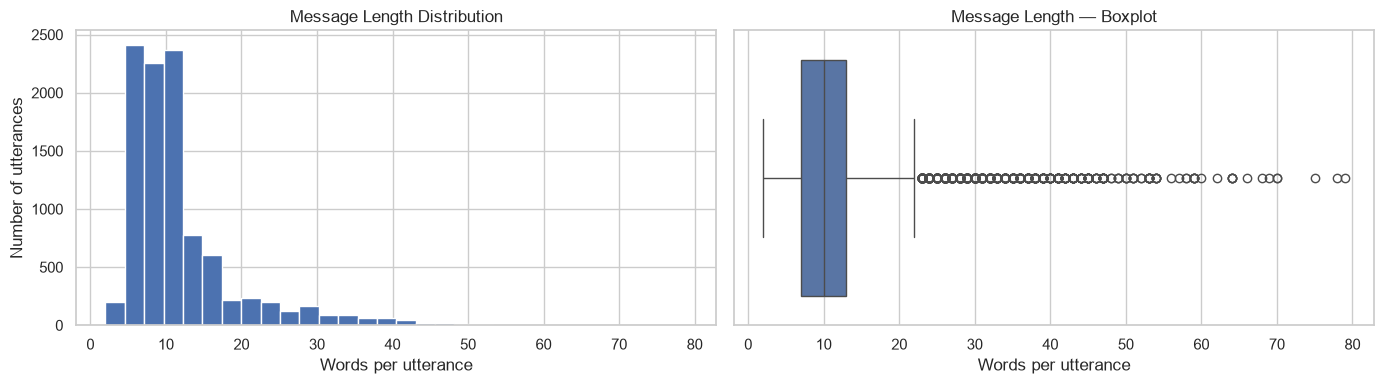

In [8]:
df["word_count"] = df["text"].str.split().str.len()
df["char_count"] = df["text"].str.len()

print("Word and character length statistics:")
display(df[["word_count", "char_count"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["word_count"], bins=30)
axes[0].set_title("Message Length Distribution")
axes[0].set_xlabel("Words per utterance")
axes[0].set_ylabel("Number of utterances")

sns.boxplot(data=df, x="word_count", ax=axes[1])
axes[1].set_title("Message Length — Boxplot")
axes[1].set_xlabel("Words per utterance")

plt.tight_layout()
plt.show()

## 7. Inspect very short and very long examples

**Why:** Summary statistics are not a substitute for reading real examples. Ask whether short messages are ambiguous and whether long messages have multiple requests. The intent label reflects the dataset's annotation, **not** guaranteed successful chatbot handling.

In [9]:
columns_to_display = ["text", "category", "word_count"]

print("Five shortest utterances:")
display(df.nsmallest(5, "word_count")[columns_to_display])

print("Five longest utterances:")
display(df.nlargest(5, "word_count")[columns_to_display])

Five shortest utterances:


,text,category,word_count
2187,Cancel Transaction,cancel_transfer,2
4847,passcode retrieval,passcode_forgotten,2
4889,Lost password,passcode_forgotten,2
5176,pending transaction?,pending_card_payment,2
5561,Transfer declined.,declined_transfer,2


Five longest utterances:


,text,category,word_count
3917,"Hearing back from us regarding your important verification results may take 10 minutes to one hour time. If verification results do fail, double-check to make sure all of your images are clear -- make sure your photos have no glare or blurring. Note: These photos need to be readable as well. You also need to be 18 years of age or older. You must be a resident of Switzerland or the European Economic Area to open a new account.",unable_to_verify_identity,79
7310,"Hi! I'm a university student studying abroad and I noticed that when I was trying to cross-reference my budget for this month that there were extra fees I was not expecting. Why is that? I've had this account for years and I haven't had any trouble so far, it might not even be on your all's end since I'm still new to international travel and finance, but I wanted to double check in case a mistake was made!",transfer_fee_charged,78
3934,"Hearing about your verification results from us may take anywhere from 10 minutes to approximately one hour. If this verification has in fact, failed, double-check to make sure that your images are clear. Also make sure that your document photos have no blur or glare. They need to be readable. You must also be 18 years of age or older and be a resident of Switzerland or the European Economic Area to open an account.",unable_to_verify_identity,75
3905,"You will hear back from us about your verification results in 10 minutes to a one hour timeframe. If these verification results do fail, please double-check to make sure your images are clear and have no glare or blur; your photos need to be fully readable. You need to be 18 years of age or older and a resident of Switzerland or the European Economic Area to create an account.",unable_to_verify_identity,70
3910,It can take between 10 minutes to an hour before you hear back from us about the verification result. Please try again if your verification fails. Make sure you double check that images are clear and all document photos are readable without blur or glare. You have to be 18 or older and live in the European Economic area or live in Switzerland to be able to open an account.,unable_to_verify_identity,70


## 8. Compare length groups and intent-level language patterns

**Why:** Segmenting the training messages provides a useful picture of the input distribution. It **does not** tell us how accurate the model is within each segment; that requires predictions on properly held-out examples.

The groups below are chosen for exploratory reporting, not because the boundaries are scientifically optimal.

,utterances,percentage
length_group,,
1–5,696,6.96
6–10,5168,51.66
11–15,2424,24.23
16–30,1279,12.79
31+,436,4.36


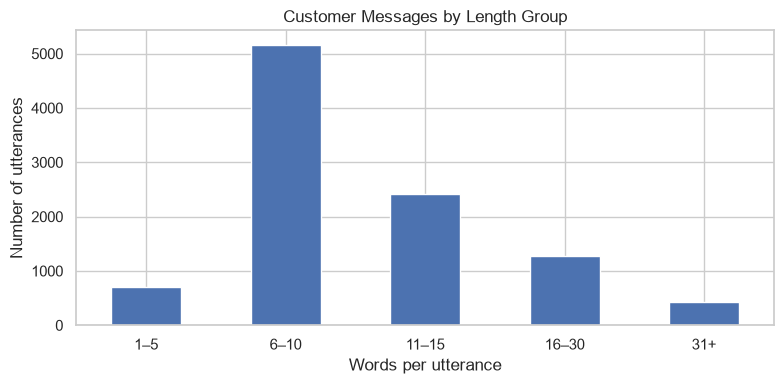

In [10]:
length_bins = [0, 5, 10, 15, 30, np.inf]
length_labels = ["1–5", "6–10", "11–15", "16–30", "31+"]
df["length_group"] = pd.cut(
    df["word_count"], bins=length_bins, labels=length_labels, include_lowest=True
)

length_distribution = df["length_group"].value_counts(sort=False).to_frame("utterances")
length_distribution["percentage"] = (
    100 * length_distribution["utterances"] / len(df)
).round(2)

display(length_distribution)

fig, ax = plt.subplots(figsize=(8, 4))
length_distribution["utterances"].plot.bar(ax=ax)
ax.set_title("Customer Messages by Length Group")
ax.set_xlabel("Words per utterance")
ax.set_ylabel("Number of utterances")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Which intent categories contain longer/shorter messages on average?
length_by_intent = (
    df.groupby("category")
    .agg(
        examples=("text", "size"),
        avg_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        max_words=("word_count", "max"),
    )
    .round(2)
)

print("Intents with the longest average messages:")
display(length_by_intent.sort_values("avg_words", ascending=False).head(10))

print("Intents with the shortest average messages:")
display(length_by_intent.sort_values("avg_words").head(10))

Intents with the longest average messages:


,examples,avg_words,median_words,max_words
category,,,,
transfer_not_received_by_recipient,171,17.55,12.0,58
transfer_fee_charged,172,17.40,11.0,78
pending_cash_withdrawal,143,16.53,11.0,64
direct_debit_payment_not_recognised,182,15.99,12.0,58
transaction_charged_twice,175,15.99,10.0,66
failed_transfer,137,15.99,10.0,54
Refund_not_showing_up,162,15.81,10.0,50
wrong_exchange_rate_for_cash_withdrawal,163,15.46,12.0,39
cash_withdrawal_not_recognised,160,15.44,12.0,40


Intents with the shortest average messages:


,examples,avg_words,median_words,max_words
category,,,,
card_acceptance,59,7.47,8.0,11
atm_support,87,7.69,8.0,13
passcode_forgotten,105,7.70,7.0,17
get_physical_card,106,7.71,7.0,17
top_up_limits,97,7.74,7.0,17
exchange_rate,112,7.83,7.0,19
order_physical_card,120,7.88,7.0,18
visa_or_mastercard,135,8.16,8.0,16
verify_top_up,126,8.31,8.0,19


## 9. Manually review potentially related intent categories

**Why:** Some category names appear related (for example, a physical card problem vs. a virtual card problem). This suggests a **possible** intent-confusion risk that we can test after model training.

We will read example utterances to form hypotheses. We cannot establish actual model confusion without a trained model and a confusion matrix.

In [12]:
# Compare a few related categories; only present categories are sampled.
intents_to_review = [
    "card_not_working",
    "virtual_card_not_working",
    "lost_or_stolen_card",
    "card_swallowed",
]

for intent in intents_to_review:
    subset = df[df["category"] == intent]
    if subset.empty:
        print(f"{intent}: not found in dataset")
        continue

    print(f"\nIntent: {intent} | Training examples: {len(subset)}")
    display(subset[["text"]].sample(n=min(3, len(subset)), random_state=42))


Intent: card_not_working | Training examples: 112


,text
1285,Something's wrong my card won't work.
1310,Currently I can't get my card to work.
1249,How do I fix a broken card?



Intent: virtual_card_not_working | Training examples: 41


,text
8191,What is the reason I got rejected for using my disposable virtual card to pay a subscription to the gym?
8180,I can't seem to get my virtual card to work.
8175,My throwaway virtual card won't work



Intent: lost_or_stolen_card | Training examples: 82


,text
1505,"My wallet was stolen, along with my cards. How do I put a freeze on my cards and order a new one?"
1475,Has there been any activity on my card today?
1497,"I thought I left my card at a restaurant, but they claim not to have it and now I don't have any idea where it is. I'm so worried that someone might be using it fraudulently. Is there any way to look into this?"



Intent: card_swallowed | Training examples: 61


,text
6245,What do I do if the ATM took my card?
6250,My card got stuck in an ATM.
6291,how can the money machine keep my card what do i need to do?


## 10. Analyst summary and next-step decisions

**What the EDA can tell us:** whether there are missing values, exact/normalized duplicate candidates, uneven intent representation, and unusual message-length patterns.

**What it cannot tell us yet:** model accuracy, real-world intent confusion, chatbot fallback rate, API execution reliability, agent handoff frequency, or self-service resolution rate.

**Next (modeling phase):** Split only the training set for model development or cross-validation; preserve the official test set for final evaluation. Compare a simple baseline model first, and use **macro F1** and per-intent precision/recall alongside accuracy.

In [13]:
# Automatically generate a small, reproducible summary of observed data.
summary = {
    "train_rows": len(train),
    "train_columns": len(train.columns),
    "test_rows": len(test),
    "intents": df["category"].nunique(),
    "missing_texts": int(train["text"].isna().sum()),
    "missing_intents": int(train["category"].isna().sum()),
    "exact_row_duplicates": int(train.duplicated().sum()),
    "exact_text_duplicates": int(train["text"].duplicated().sum()),
    "normalized_text_duplicates": int(normalized_duplicate_count),
    "train_test_text_overlap": len(overlap),
    "mean_words": round(df["word_count"].mean(), 2),
    "median_words": float(df["word_count"].median()),
    "max_words": int(df["word_count"].max()),
    "smallest_intent_class": int(intent_counts.min()),
    "largest_intent_class": int(intent_counts.max()),
}

display(pd.Series(summary, name="EDA result").to_frame())

,EDA result
train_rows,10003.00
train_columns,2.00
test_rows,3080.00
intents,77.00
missing_texts,0.00
missing_intents,0.00
exact_row_duplicates,0.00
exact_text_duplicates,0.00
normalized_text_duplicates,4.00
train_test_text_overlap,7.00


### Reflection questions

1. Which intent classes have relatively few examples? How could this affect model evaluation?
   
   The least represented intents are `contactless_not_working` (35), `virtual_card_not_working` (41), and `card_acceptance` (59). These classes may be more challenging for the model to learn due to limited training examples, potentially resulting in lower recall and F1-scores. Therefore, class-level performance should be evaluated carefully.

2. Are there meaningful data-quality issues, or only clean results for the basic checks?

    The dataset contains no missing values or exact duplicates, indicating good overall data quality. However, 4 normalized-text duplicates and 7 overlapping texts between training and test sets were detected. These overlaps may cause data leakage and inflate model performance metrics. Therefore, they should be investigated before model training and evaluation.

3. Does the message-length histogram look right-skewed? What evidence supports your answer?

    The message length distribution is strongly right-skewed (skewness = 2.61). Most customer messages contain approximately 5–15 words, while a small number of longer messages increase the mean (11.95) above the median (10). Longer messages may introduce additional complexity for intent classification, but this hypothesis needs to be validated through model evaluation.

4. Which **two** intents might a model confuse, based on actual message examples?

    The `card_not_working` and `virtual_card_not_working` intents are semantically similar because both describe card functionality issues. The main distinguishing feature is the presence of keywords such as "virtual" or "disposable". The model may confuse these intents when the card type is not explicitly mentioned, potentially reducing classification accuracy.

5. Why would it be misleading to calculate **fallback rate** or **self-service resolution rate** from BANKING77?

    It contains customer utterances and their corresponding intent labels, but it does not include real chatbot interactions, fallback events, or conversation outcomes. Therefore, we cannot calculate actual Fallback Rate or Self-Service Resolution Rate without additional operational data.

6. Which KPI would you present to a Product Owner **after** training a baseline classifier, and why?

    Prioritize Macro F1-Score because the dataset contains 77 intent classes with different sample sizes. Macro F1 gives equal importance to each intent, helping identify underperforming categories. I would also report overall Accuracy and per-intent Precision and Recall to highlight improvement opportunities.